# 02-机械臂电机原理与选型


## 1. 本篇范围与要解决的问题

上一笔记把具身智能描述为“感知—决策—行动—反馈”的闭环。本篇进入行动环节：**控制器发出指令后，机械臂怎样真正产生运动？**

课件从三个常见对象开始比较：舵机、步进电机和直流无刷电机（BLDC）。比较不只是“哪一种更好”，而是要回答：

- 电机怎样产生旋转？
- 控制器究竟向它发送什么？
- 系统怎样知道动作有没有完成？
- 速度、扭矩、精度、成本和控制复杂度怎样取舍？

本篇依据 `具身智能实战01.pptx` 第 **46—76页**整理，覆盖课程的电机驱动、舵机、步进电机、BLDC和三者对比内容。第77页开始的齿轮传动留给第03篇。

课件后续会继续讨论减速器、编码器和PID。这里先把电机与控制方式的关系建立起来，避免把“电机本体”“驱动器”“传感器”和“完整伺服系统”混为一谈。


## 2. 从数字指令到物理动作

在数字世界里，行动可能只是执行一行代码；在机械臂中，一条指令要经过多层转换：

```text
任务要求
  → 运动目标（位置、角度或速度）
  → 控制器与驱动信号
  → 电机产生转矩
  → 传动机构放大或传递转矩
  → 关节和连杆运动
  → 传感器反馈实际状态
```

课件把这一段称为从数字指令到精确物理动作的技术鸿沟。本篇主要关注中间的**驱动技术**。

电机选型不能只看额定功率或价格。机械臂关节还要考虑输出扭矩、转速、定位方式、反馈能力、负载变化、响应速度、布线和控制器实现难度。一个低成本电机如果无法稳定完成目标动作，系统整体成本反而会增加。


## 3. 三类电机的比较框架

课件对三种电机从工作原理、控制方式、性能特性和应用场景四个方面展开。

| 类型 | 课件中的核心印象 | 典型输入 | 是否自带位置闭环 | 典型优势 |
|---|---|---|---|---|
| 舵机（Servo） | 电机、传动、传感、控制集成在一起的系统 | 目标角度对应的PWM信号 | 普通舵机通常有 | 使用简单、体积小、输出扭矩较大 |
| 步进电机（Stepper） | 按离散步数运动的执行器 | STEP/PUL脉冲与DIR方向 | 通常没有 | 结构简单、定位直观、驱动器成熟 |
| 直流无刷电机（BLDC） | 通过电子换向实现连续高速旋转 | 电调或伺服驱动器的控制信号 | BLDC本体不一定有，伺服系统需要 | 高效率、高转速、长寿命、高功率密度 |

表中的“舵机”与“BLDC伺服系统”不是同一层概念。舵机通常指已经集成控制与反馈的模块；BLDC是电机本体，配合编码器和伺服驱动器后才构成完整的位置伺服系统。


## 4. 舵机：一个集成的闭环执行系统

### 4.1 舵机不只是电机

课件的关键表述是：**舵机不是一种电机类型，而是一个系统。**

一个常见舵机通常包含四部分：

| 组成 | 作用 |
|---|---|
| 直流电机 | 提供原始旋转动力，通常转速较高、直接输出扭矩有限 |
| 减速齿轮组 | 降低转速、放大输出扭矩，把动力传到输出轴 |
| 位置传感器 | 测量输出轴或齿轮的当前角度，普通低成本舵机常使用电位器 |
| 控制电路 | 解析目标信号，比较目标角度与当前角度，并驱动电机修正误差 |

因此，用户看到的是一个可以接收目标位置的执行模块，内部已经完成了一部分驱动、传动、测量和控制工作。

### 4.2 舵机内部的闭环

```text
目标角度
   ↓
控制电路 → 直流电机 → 减速齿轮 → 输出轴
   ↑                              ↓
   └──────── 位置传感器反馈 ────────┘
```

控制电路把外部要求转换为目标角度，再读取传感器给出的当前角度。两者相减得到误差：

```text
Error = Target - Current
```

误差不为零时，控制电路驱动电机正转或反转；误差接近零时，输出逐渐减小。课件用这个过程说明舵机“给一个目标，它自己过去”的便利性。

**边界：**舵机内部有闭环，并不代表它能达到任意精度。传感器分辨率、齿轮回差、死区、负载和内部控制参数都会影响最终位置。


### 4.3 PWM：舵机的常见控制信号

PWM（Pulse Width Modulation，脉冲宽度调制）用周期性方波的高电平持续时间表示控制量。课件用一个标准周期示意：周期约为 `20 ms`，改变高电平脉冲宽度，对应不同的目标角度。

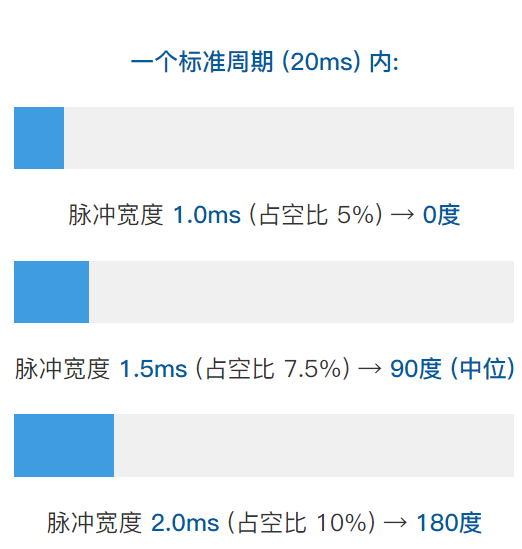

*来源：`具身智能实战01.pptx` 第53页原图。示例展示 `1.0 ms`、`1.5 ms` 和 `2.0 ms` 脉宽分别对应约 `0°`、`90°` 和 `180°`。*

按图中的示例：

| 周期内脉宽 | 占空比（以20 ms周期计算） | 示例目标角度 |
|---:|---:|---:|
| `1.0 ms` | `5%` | `0°` |
| `1.5 ms` | `7.5%` | `90°`，中位 |
| `2.0 ms` | `10%` | `180°` |

这是课件中的示例范围，不应直接当作所有舵机的通用规格。不同型号的脉宽范围、周期、机械限位和角度映射可能不同，实际使用要以具体舵机资料为准。发送超出机械范围的目标可能导致撞限、发热或损坏。

**易错点：**PWM 的频率和脉宽都重要。仅说“占空比为10%”并不能脱离周期确定脉宽；在周期不同的情况下，同样的占空比可能代表不同的高电平时间。


### 4.4 普通舵机的优点与局限

| 方面 | 课件内容 | 对机械臂设计的影响 |
|---|---|---|
| 使用简单 | 上层发送目标角度，不必自己搭建完整反馈回路 | 适合教学、原型和快速验证 |
| 位置闭环 | 能根据反馈抵抗一定外部扰动 | 比纯开环电机更容易保持目标位置 |
| 集成度与成本 | 电机、齿轮、传感与控制电路集成 | 减少外部器件和开发工作 |
| 输出扭矩 | 内置减速器，小体积可获得较大扭矩 | 适合桌面级机械臂关节 |
| 精度 | 存在死区、回差，精度有限 | 不适合要求很高的工业定位 |
| 响应 | 内部PID等参数通常固定，难以精细调整加减速 | 难以针对复杂负载做完整的运动性能优化 |
| 寿命与噪声 | 齿轮，特别是塑料齿轮，会磨损并产生噪声 | 需要控制负载、速度和工作周期 |
| 布线 | 传统多舵机方案每个舵机通常需要独立控制线 | 关节数量增加后，布线和通信管理变复杂 |

课件另外展示了黑马总线舵机，说明总线方案可以改善部分传统舵机的布线和控制问题。具体协议、地址和参数不在本页展开，不能根据图片推断出未给出的通信细节。

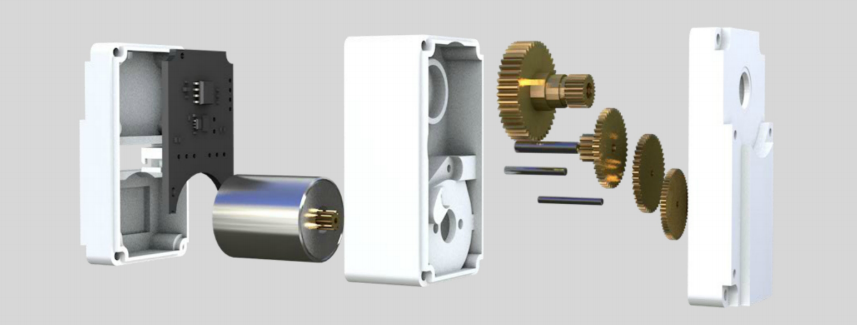

*来源：`具身智能实战01.pptx` 第57页原图。这里只保留结构示意，用于说明总线舵机作为课程中的改进方向。*

### 4.5 为什么课程机械臂选择舵机

课程机械臂选择舵机的主要原因是：**降低硬件和底层控制门槛，把学习重点放到上层的运动学、视觉与AI算法。**

它适合：

- 教学机器人关节与原型验证；
- 航模、车模中的云台和转向系统；
- 开关、阀门等简单执行机构。

它不适合直接替代需要高精度、高动态响应和高可靠性的工业关节。选型要看任务要求，而不是因为“闭环”两个字就默认性能足够。


## 5. 步进电机：按步数运动的执行器

### 5.1 离散运动原理

步进电机通过依次给不同相的线圈通电，形成变化的磁场，转子在磁场牵引下逐步转动。课件用A相、B相、C相依次通电说明了“走一步”的过程。

理想情况下，转角由步数和步距角决定：

```text
转过的角度 = 步数 × 步距角
```

例如，某电机每步转 `1.8°`，控制器发送 `100` 个有效步进脉冲，理论转角是 `180°`。实际系统还要考虑细分、负载、加减速和可能的失步。

### 5.2 开环控制：控制器不验证结果

步进系统的典型结构是：

```text
控制器（如MCU） → 驱动器 → 步进电机
```

控制器发出两类主要信号：

| 信号 | 作用 |
|---|---|
| `PUL`／`STEP` | 每个有效脉冲代表一步；脉冲频率主要影响转速 |
| `DIR` | 用高低电平选择正转或反转 |

典型步进控制是开环：控制器认为电机已经执行了要求，不读取实际位置进行纠正。负载过大、加速过快或速度过高时，电机可能失步；开环控制器通常不知道失步已经发生。

### 5.3 微步技术

标准步进可以理解为各相线圈按较粗的通断顺序工作。微步（Microstepping）通过更细致地控制不同相线圈的电流比例，把一个物理步距角细分成更多更小的步。

| 作用 | 结果 |
|---|---|
| 细分角度 | 运动更细腻，理论分辨率提高 |
| 平滑电流变化 | 降低低速振动与噪声 |
| 代价 | 细分状态下可用扭矩会有所下降，微步数也不等于同等比例的绝对定位精度 |

最后一点很重要：微步提高了命令分辨率和运动平滑度，但受到电机磁路、驱动器电流精度、负载与机械间隙影响，不能简单地把“细分数”当作实际精度。

### 5.4 步进电机的优缺点与应用

| 优点 | 局限 |
|---|---|
| 结构和驱动方式相对简单 | 负载过大或速度过快会失步 |
| 不失步时位置控制直观 | 开环系统无法自行发现位置误差 |
| 静止时可以提供保持扭矩 | 线圈可能持续通电，发热和效率问题明显 |
| 适合低速定位 | 速度升高后扭矩下降较快，低速可能有振动和噪声 |

课件列举的应用包括3D打印机的X/Y/Z轴、激光切割机、CNC定位平台、医疗设备和分析仪器。共同点是：需要位置运动，负载变化相对可控，能够接受开环方案的风险，或系统另有回零、限位等保护机制。


## 6. 舵机与步进电机的关键差异

课件用“关心去到哪”和“关心走几步”概括两者的控制思想。

| 对比项 | 舵机 | 步进电机 |
|---|---|---|
| 控制目标 | 目标角度 | 步数与方向 |
| 反馈 | 普通舵机内部有位置反馈 | 通常没有位置反馈 |
| 控制结构 | 位置闭环 | 典型为位置开环 |
| 失误表现 | 可能有死区、回差或达不到目标 | 可能失步，控制器通常不知道 |
| 上层使用 | 发送目标位置即可 | 需要处理脉冲数量、频率、方向和加减速 |
| 典型强项 | 简单、抗一定扰动、集成度高 | 结构简单、定位命令直观 |
| 典型场景 | 教学机械臂、云台、转向 | 3D打印机、CNC、定位平台 |

“闭环”不等于“无误差”，“开环”也不等于“完全不能定位”。表格描述的是典型系统结构，实际产品可能加入编码器、限位开关或外部校准，使控制结构发生变化。


## 7. BLDC：电子换向与高性能旋转

### 7.1 有刷与无刷的区别

有刷直流电机通过电刷和换向器机械地改变电流方向。BLDC取消了这组容易磨损的机械换向部件，由外部控制器或电调（ESC）按顺序给线圈通电，形成旋转磁场，带动永磁体转子旋转。

因此，BLDC具有课件强调的特点：

- 没有电刷磨损，寿命更长；
- 能达到较高转速和效率；
- 功率密度较高，适合持续旋转。

但“无刷”只说明电机的换向方式，不自动说明它具备高精度位置控制。控制器、传感器和算法决定了整套系统的控制能力。

### 7.2 控制器为什么需要知道转子位置

电子换向必须知道当前转子磁极位置，才能决定下一步给哪些线圈通电。课件介绍两类方式：

| 方式 | 怎样获取位置 | 课件强调的特点 |
|---|---|---|
| 有感控制 | 使用电机内部霍尔传感器直接检测转子磁极位置 | 启动平稳，低速性能较好 |
| 无感控制 | 根据未通电线圈的反电动势估算转子位置 | 结构和成本较简单，但低速与启动判断更困难 |

课件提到FOC等算法用于无感位置估算。这里的重点是“换向需要位置依据”，而不是把FOC简单等同于所有BLDC控制方式。

### 7.3 BLDC本体与伺服系统

BLDC本身通常更擅长速度或力矩控制。若要让它成为工业机器人关节常见的高精度位置执行系统，还需要位置反馈与相应的伺服驱动器。

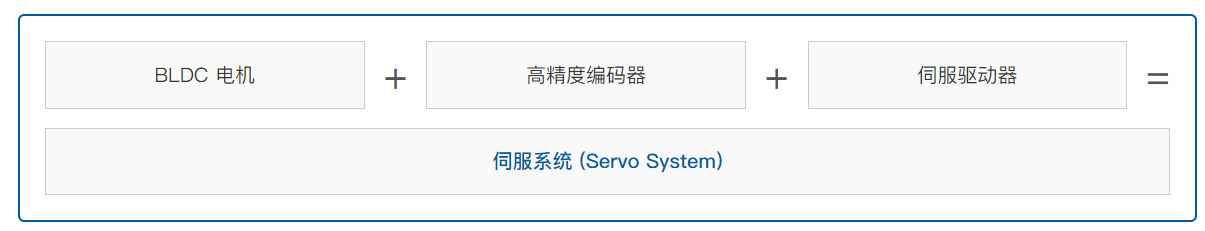

*来源：`具身智能实战01.pptx` 第73页原图。课件用“BLDC电机＋高精度编码器＋伺服驱动器”表示伺服系统。*

课件给出的系统关系可以记为：

```text
BLDC电机 + 高精度编码器 + 伺服驱动器 = 伺服系统
```

编码器测量实际位置，伺服驱动器根据目标与反馈计算控制输出。相比普通舵机，这种方案把电机、传感器和控制器分开，性能上限更高，但成本、布线、调试和控制算法复杂度也更高。

### 7.4 BLDC的性能与应用

| 课件强调的性能 | 典型应用 |
|---|---|
| 高效率、高转速 | 无人机、电动车 |
| 长寿命、高功率密度 | 高性能风扇 |
| 加入编码器和伺服驱动后可做高性能位置关节 | 工业机器人高端关节 |

如果任务只需要持续高速旋转，BLDC加速度或力矩控制可能已经足够；如果任务要求精确位置，需要继续考虑编码器、驱动器和闭环控制方案。


## 8. 三者横向选型

课件最后把舵机、步进电机和BLDC伺服放到同一张表中比较。

| 特性 | 舵机 | 步进电机 | BLDC＋伺服驱动 |
|---|---|---|---|
| 典型控制方式 | 位置闭环，常见PWM输入 | 位置开环，STEP/PUL＋DIR | 速度、力矩、位置闭环 |
| 核心优势 | 集成度高、使用简单、成本较低 | 结构简单、位置命令直观 | 高速、高效率、高响应、高精度潜力 |
| 核心劣势 | 精度和响应能力有限，存在回差 | 可能失步，效率和高速性能受限 | 系统复杂、成本高、需要更多外设 |
| 反馈需求 | 通常已内置 | 通常没有，常需回零或外部保护 | 需要编码器等位置反馈实现位置伺服 |
| 控制器负担 | 较低 | 需要生成脉冲并管理速度曲线 | 需要处理反馈、换向和伺服算法 |
| 典型场景 | 教学机械臂、原型、云台 | 3D打印机、CNC和定位平台 | 工业机器人、高性能运动系统、无人机驱动 |

可以先按任务约束筛选：

1. 如果重点是快速做出桌面级原型，并希望减少底层控制工作，优先考虑集成式舵机。
2. 如果需要低速定位、结构简单，且负载变化可控，可以考虑步进电机，同时设计回零、限位和失步风险处理。
3. 如果需要高速、连续运动、高效率和高动态响应，应考虑BLDC；如果还要高精度位置控制，则要按完整伺服系统选型。

这不是固定规则。最终还要核对关节负载、工作空间、运动速度、定位误差、供电、散热、通信和预算。


## 9. 选型时应记录的工程约束

课件最后的结论是“没有最好的电机，只有最合适的电机”。为了把这句话落实成工程判断，可以在选型表中至少记录：

| 约束 | 需要明确的问题 |
|---|---|
| 负载与扭矩 | 关节要带动多重的连杆和末端负载？启动、加速和保持时需要多大扭矩？ |
| 速度与加速度 | 需要慢速精细定位，还是快速连续运动？允许多大的加速度变化？ |
| 位置精度 | 允许的角度误差、回差和重复定位误差是多少？ |
| 反馈 | 只需要命令计数，还是必须知道真实角度和速度？ |
| 控制复杂度 | 团队是否能实现驱动、采样、闭环、故障保护与调试？ |
| 机械与热 | 齿轮寿命、保持发热、散热空间和噪声是否符合要求？ |
| 供电与通信 | 电压、电流峰值、线缆数量、总线或PWM接口是否匹配？ |
| 成本与维护 | 初始成本、易损件、替换难度和长期维护成本如何？ |

**选型的顺序应从任务倒推，而不是从电机名称正推。**先写清楚机械臂要完成的动作和误差边界，再比较可实现这些约束的方案。


## 10. 课件要点回顾

1. 舵机是电机、减速器、位置传感器和控制电路的集成系统，普通舵机通常通过PWM接收目标角度。
2. 舵机内部闭环可以降低使用门槛，但死区、回差、内部参数和齿轮寿命限制了它的精度和响应。
3. 步进电机按步数和步距角运动，典型系统通过STEP/PUL与DIR控制，开环结构存在失步风险。
4. 微步可以让步进运动更平滑、命令分辨率更高，但不等于绝对定位精度按相同比例提高。
5. BLDC通过电子换向获得高效率、高转速和长寿命；要实现高精度位置控制，通常还需要编码器和伺服驱动器。
6. 电机选型是在成本、性能和控制复杂度之间做权衡，不能脱离任务要求比较“哪种最好”。

下一篇进入机械传动与位置反馈，继续回答两个问题：电机为什么需要减速器，机械臂又怎样知道关节实际转到了哪里？


## 11. 来源与覆盖范围

资料来自[用户提供的课程网盘](https://pan.baidu.com/s/1JTzTYgpIAiSUroQ2-ihJHA?pwd=1234)，提取码为 `1234`。资料路径为“6、嵌入式具身智能机械臂／视频资料／课程ppt”。

| 笔记章节 | 对应课件页码 |
|---|---|
| 驱动问题与三类电机 | 46—49 |
| 舵机组成、闭环、PWM、优缺点与场景 | 50—59 |
| 步进原理、开环、脉冲方向、微步与应用 | 60—68 |
| BLDC电子换向、转子位置、伺服系统与应用 | 69—74 |
| 三者比较与选型原则 | 75—76 |

本篇保留了第53、57、73页中对理解有帮助的原图；第57页图只用于说明总线舵机作为改进方向，未据图推断具体协议或参数。
